# 03 - Estensione ad altri pazienti virtuali (adult#001, #002, #003)

**Obiettivo.** Ripetere il confronto su altri pazienti virtuali con le stesse condizioni del notebook 02 (stessi guadagni
e parametri, pasto non annunciato alle 12:00, stesso seme). I controllori **non** vengono ritarati sul singolo paziente:
cambiano solo le grandezze che dipendono dal basale del paziente (limiti dell'integrale e tetto IOB).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import aid_sim as A, notebook_utils as U
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
SEED = 1                                  # seme del rumore del sensore (uguale per tutti i controllori)
COL = {"PID senza AW": "tab:gray", "PID": "tab:red", "PID cons.": "tab:orange",
       "PID+PLGS": "tab:green", "PID+IOB": "tab:purple", "PID+IOB+PLGS": "tab:blue"}
print("Versioni delle librerie usate:"); display(U.library_versions())

Versioni delle librerie usate:


,Pacchetto,Versione
0,Python,3.13.16
1,simglucose,0.2.11
2,numpy,2.4.4
3,scipy,1.17.1
4,pandas,3.0.2
5,matplotlib,3.10.8


In [2]:
def finestra(df):
    """Solo la finestra di analisi (08:00-24:00): l'assestamento 00:00-08:00 non entra né nei grafici né nelle metriche."""
    return df[df.t_h >= A.WARMUP_H]

def decora(ax, meal_h=A.MEAL_CLOCK_H, banda=True):
    """Linea del pasto e griglia; banda 70-180 mg/dL solo sui pannelli di glicemia."""
    if banda:
        ax.axhspan(70, 180, color="green", alpha=0.12)
    ax.axvline(meal_h, color="k", ls=":", lw=1.2); ax.grid(ls=":", alpha=0.5)

def tabella(risultati, chiavi):
    """risultati: dict {chiave: DataFrame}; chiavi: nomi delle colonne-indice per la tabella."""
    rows = []
    for k, df in risultati.items():
        k = k if isinstance(k, tuple) else (k,)
        rows.append({**dict(zip(chiavi, k)), **{m: round(float(v), 1) for m, v in A.metrics(df).items()}})
    return pd.DataFrame(rows)

## 1. Configurazione
### 1.1 Pazienti (parametri di simglucose)

In [3]:
import os, simglucose
PAZ = ["adult#001", "adult#002", "adult#003"]
q = pd.read_csv(os.path.join(os.path.dirname(simglucose.__file__), "params", "Quest.csv")).set_index("Name")
rows = []
for p in PAZ:
    ic = U.initial_conditions(p, SEED)
    rows.append({"Paziente": p, "BW [kg]": round(ic["BW"], 1), "Gb [mg/dL]": round(ic["Gb"], 1), "u_b [U/h]": round(ic["ub"] * 60, 2),
                 "CR [g/U]": q.loc[p, "CR"], "CF [mg/dL/U]": round(q.loc[p, "CF"], 1), "TDI [U/die]": round(q.loc[p, "TDI"], 1),
                 "kabs [1/min]": round(ic["kabs"], 4)})
display(pd.DataFrame(rows))

,Paziente,BW [kg],Gb [mg/dL],u_b [U/h],CR [g/U],CF [mg/dL/U],TDI [U/die],kabs [1/min]
0,adult#001,102.3,138.6,1.27,10,8.8,50.4,0.0891
1,adult#002,111.1,136.4,1.37,8,9.2,57.9,0.0214
2,adult#003,81.6,147.1,1.43,9,17.9,56.4,0.1697


### 1.2 Scenario e controllori

In [4]:
display(U.scenario_table("adult#001", "0, 60 o 90", SEED).iloc[6:])
NOMI = ["PID senza AW", "PID", "PID cons.", "PID+IOB+PLGS"]
for p in PAZ:
    ub_p = U.initial_conditions(p, SEED)["ub"]
    t = U.controller_table(A.CFG["PID+IOB+PLGS"], ub_p).set_index("Parametro").loc[["I_min, I_max (derivati)", "Ki*I_min, Ki*I_max", "iob_max (derivato)"]]
    print(p, "- grandezze che dipendono dal basale (PID+IOB+PLGS):"); display(t)

,Voce,Valore,Unita'
6,Seme casuale del sensore,1,-
7,Inizio simulazione,00:00,ora del giorno
8,Assestamento escluso dalle metriche,00:00-08:00,ora del giorno
9,Finestra di analisi,08:00-24:00,ora del giorno
10,Passo di campionamento dt,3.0,min
11,Passi totali / nella finestra,480 / 320,-
12,Glicemia plasmatica iniziale (00:00),138.6,mg/dL
13,Misura CGM iniziale (00:00),152.0,mg/dL
14,"Stati iniziali stimatore IOB (S1, S2)","0.0, 0.0",U
15,Orario del pasto,12:00,ora del giorno


adult#001 - grandezze che dipendono dal basale (PID+IOB+PLGS):


,Valore,Unita',Significato
Parametro,,,
"I_min, I_max (derivati)",-1056 ; 4225,mg*min/dL,Limiti effettivi dell'integrale dell'errore
"Ki*I_min, Ki*I_max",-0.32 ; 1.27,U/h,Contributo minimo e massimo dell'azione integrale
iob_max (derivato),1.9,U,Tetto IOB effettivo (attivo solo se use_iob=True)


adult#002 - grandezze che dipendono dal basale (PID+IOB+PLGS):


,Valore,Unita',Significato
Parametro,,,
"I_min, I_max (derivati)",-1141 ; 4565,mg*min/dL,Limiti effettivi dell'integrale dell'errore
"Ki*I_min, Ki*I_max",-0.34 ; 1.37,U/h,Contributo minimo e massimo dell'azione integrale
iob_max (derivato),2.05,U,Tetto IOB effettivo (attivo solo se use_iob=True)


adult#003 - grandezze che dipendono dal basale (PID+IOB+PLGS):


,Valore,Unita',Significato
Parametro,,,
"I_min, I_max (derivati)",-1188 ; 4751,mg*min/dL,Limiti effettivi dell'integrale dell'errore
"Ki*I_min, Ki*I_max",-0.36 ; 1.43,U/h,Contributo minimo e massimo dell'azione integrale
iob_max (derivato),2.14,U,Tetto IOB effettivo (attivo solo se use_iob=True)


### Unità di misura delle variabili salvate
| Variabile | Unità | Significato |
|---|---|---|
| `t_h` | h | ora del giorno (la simulazione parte alle 00:00) |
| `CGM` | mg/dL | misura del sensore, con rumore: è l'unica grandezza vista dal controllore |
| `BG` | mg/dL | glicemia plasmatica del modello UVa/Padova (Gp/Vg), usata per le metriche |
| `Gsub` | mg/dL | glicemia sottocutanea senza rumore (`info['bg']` di simglucose) |
| `Insulin_Uh` | U/h | velocità di infusione comandata |
| `IOB` | U | insulina attiva netta stimata dal controllore (eccesso rispetto al basale) |
| `IOB_vero` | U | insulina sottocutanea netta del modello (Isc1 + Isc2 meno l'equilibrio basale) |
| `Vincolo` | - | vincolo attivo nel passo: `iob`, `plgs`, `sat_alta`, `sat_bassa` o vuoto |

Metriche: TIR, TAR, TBR in % del tempo nella finestra 08:00-24:00; `TIR_post6h` nelle 6 h dopo il pasto;
`TBR_tardivo` dalle 3 h dopo il pasto alle 24:00; picco e nadir in mg/dL; `insulina_tot` in U nella finestra.

## 2. Verifica a digiuno e pasti da 60 e 90 g

In [5]:
CARICHI = [0.0, 60.0, 90.0]
R = {(p, int(c), n): A.simulate(p, c, A.CFG[n], seed=SEED)[0] for p in PAZ for c in CARICHI for n in NOMI}
print(len(R), "simulazioni completate")

36 simulazioni completate


## 3. Grafici (60 g): glicemia e IOB per paziente

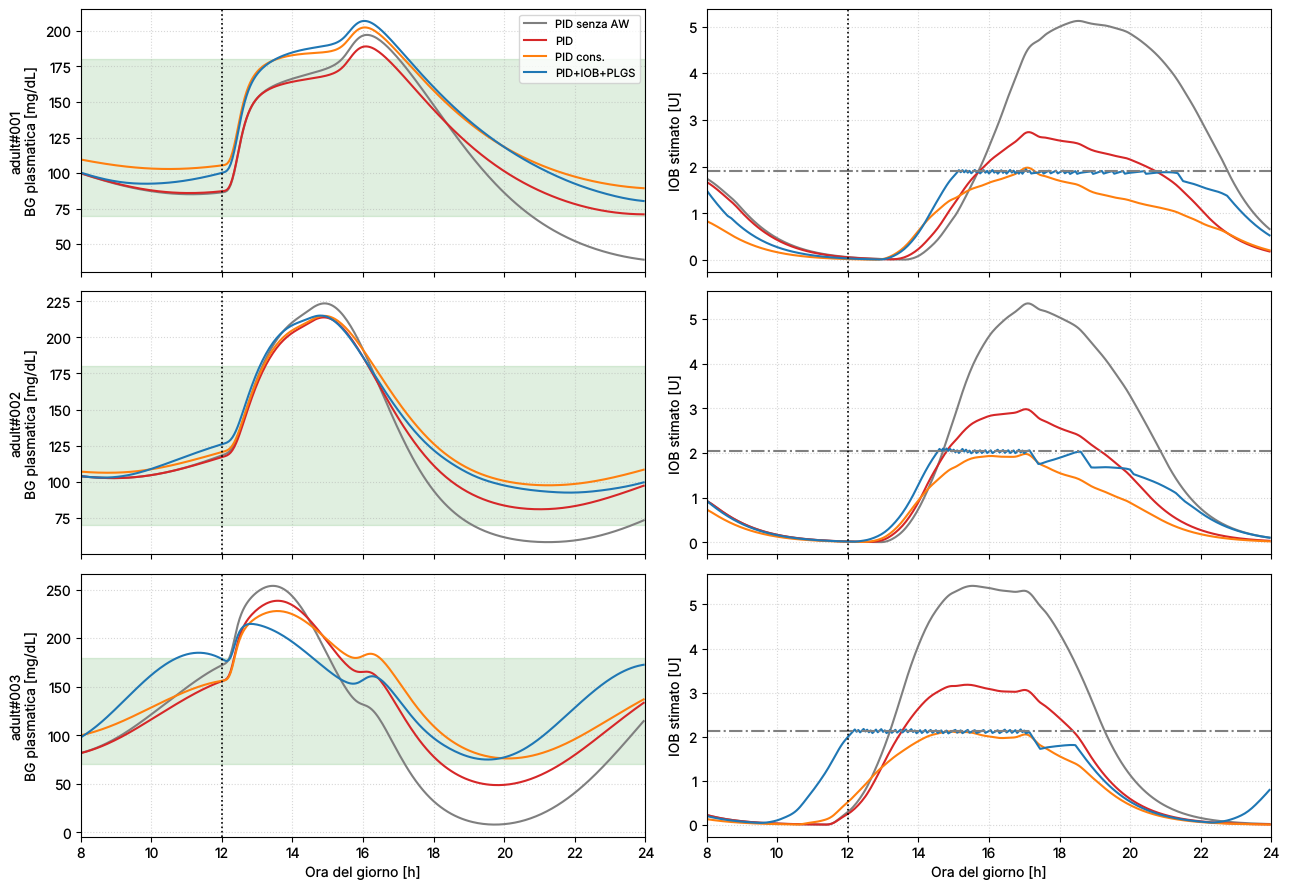

In [6]:
fig, ax = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
for i, p in enumerate(PAZ):
    ub_p = U.initial_conditions(p, SEED)["ub"]
    for n in NOMI:
        d = finestra(R[(p, 60, n)])
        ax[i, 0].plot(d.t_h, d.BG, color=COL[n], label=n); ax[i, 1].plot(d.t_h, d.IOB, color=COL[n])
    ax[i, 1].axhline(1.5 * ub_p * 60, color="gray", ls="-.")
    decora(ax[i, 0]); decora(ax[i, 1], banda=False)
    ax[i, 0].set_ylabel(f"{p}\nBG plasmatica [mg/dL]"); ax[i, 1].set_ylabel("IOB stimato [U]")
ax[0, 0].legend(fontsize=8); ax[2, 0].set_xlabel("Ora del giorno [h]"); ax[2, 1].set_xlabel("Ora del giorno [h]")
ax[2, 0].set_xlim(A.WARMUP_H, A.ANALYSIS_END_H); plt.tight_layout(); plt.show()

## 4. Indicatori clinici

In [7]:
T = tabella(R, ["Paziente", "CHO [g]", "Controllore"])
for c in [0, 60, 90]:
    print(f"Pasto da {c} g:" if c else "A digiuno (0 g):")
    display(T[T["CHO [g]"] == c].drop(columns="CHO [g]").reset_index(drop=True))

A digiuno (0 g):


,Paziente,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot,IAE,IAE_post6h,IAE_range,t_rientro,n_commut,n_sosp,TV_u,std_u
0,adult#001,PID senza AW,100.0,0.0,0.0,0.0,0.0,0.0,100.0,148.9,85.1,24.5,352.5,98.4,0.0,0.0,0.0,0.0,9.2,1.1
1,adult#001,PID,100.0,0.0,0.0,0.0,0.0,0.0,100.0,136.2,85.9,21.7,295.5,99.9,0.0,0.0,0.0,0.0,8.3,0.6
2,adult#001,PID cons.,100.0,0.0,0.0,0.0,0.0,0.0,100.0,132.7,102.9,23.4,150.8,45.7,0.0,0.0,0.0,0.0,7.7,0.5
3,adult#001,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,0.0,100.0,137.5,92.5,24.4,229.5,62.3,0.0,0.0,31.0,5.0,46.2,0.9
4,adult#002,PID senza AW,100.0,0.0,0.0,0.0,0.0,0.0,100.0,139.5,84.2,27.6,281.9,74.3,0.0,0.0,0.0,0.0,9.3,0.8
5,adult#002,PID,100.0,0.0,0.0,0.0,0.0,0.0,100.0,130.9,91.7,26.2,220.5,39.2,0.0,0.0,0.0,0.0,8.2,0.6
6,adult#002,PID cons.,100.0,0.0,0.0,0.0,0.0,0.0,100.0,131.3,105.8,23.9,145.5,41.8,0.0,0.0,0.0,0.0,7.6,0.4
7,adult#002,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,0.0,100.0,133.7,99.6,24.6,202.3,54.9,0.0,0.0,9.0,4.0,22.6,0.8
8,adult#003,PID senza AW,64.7,0.0,0.0,35.3,29.1,62.8,70.8,179.4,21.3,29.8,774.9,291.5,184.5,9.9,0.0,0.0,11.0,1.5
9,adult#003,PID,82.2,0.0,0.0,17.8,0.0,31.7,89.2,161.4,59.1,26.8,490.8,191.2,20.7,8.2,0.0,0.0,9.2,0.8


Pasto da 60 g:


,Paziente,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot,IAE,IAE_post6h,IAE_range,t_rientro,n_commut,n_sosp,TV_u,std_u
0,adult#001,PID senza AW,69.7,10.3,0.0,20.0,13.4,35.6,72.5,197.2,39.1,36.8,705.1,293.7,80.1,NaN,0.0,0.0,13.4,1.5
1,adult#001,PID,93.4,6.6,0.0,0.0,0.0,0.0,82.5,189.1,70.9,28.4,566.0,267.7,6.4,4.7,0.0,0.0,9.8,0.8
2,adult#001,PID cons.,77.2,22.8,0.0,0.0,0.0,0.0,39.2,202.5,89.3,26.4,522.9,346.6,34.0,5.2,0.0,0.0,8.7,0.6
3,adult#001,PID+IOB+PLGS,76.6,23.4,0.0,0.0,0.0,0.0,37.5,207.0,80.3,25.7,598.2,361.8,47.4,5.3,68.0,5.0,118.0,1.1
4,adult#002,PID senza AW,52.5,19.4,0.0,28.1,0.0,50.0,48.3,223.5,58.3,35.2,715.1,338.9,122.3,11.6,0.0,0.0,13.2,1.6
5,adult#002,PID,81.6,18.4,0.0,0.0,0.0,0.0,50.8,213.8,81.0,28.9,554.9,313.4,63.7,4.2,0.0,0.0,10.0,0.9
6,adult#002,PID cons.,80.3,19.7,0.0,0.0,0.0,0.0,47.5,214.9,97.6,26.2,476.9,340.6,70.8,4.4,0.0,0.0,8.6,0.6
7,adult#002,PID+IOB+PLGS,80.6,19.4,0.0,0.0,0.0,0.0,48.3,215.1,92.6,27.0,505.7,338.5,72.0,4.2,52.0,6.0,102.7,1.0
8,adult#003,PID senza AW,46.9,17.5,4.4,35.6,30.9,63.3,40.0,253.9,7.9,34.9,1029.7,429.7,381.7,10.9,0.0,0.0,12.3,1.8
9,adult#003,PID,60.3,18.8,0.0,20.9,10.6,37.2,50.0,238.5,48.6,29.6,759.1,397.1,165.0,9.6,0.0,0.0,9.8,1.1


Pasto da 90 g:


,Paziente,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot,IAE,IAE_post6h,IAE_range,t_rientro,n_commut,n_sosp,TV_u,std_u
0,adult#001,PID senza AW,48.4,27.8,0.0,23.8,18.4,42.2,25.8,232.8,32.4,38.2,906.1,445.0,218.0,NaN,0.0,0.0,13.8,1.7
1,adult#001,PID,61.6,28.1,0.0,10.3,0.0,18.3,25.0,226.1,64.8,29.9,758.8,431.2,111.3,NaN,0.0,0.0,10.6,0.9
2,adult#001,PID cons.,67.5,32.5,0.0,0.0,0.0,0.0,13.3,241.9,84.2,27.6,728.8,520.5,190.0,5.9,0.0,0.0,9.0,0.7
3,adult#001,PID+IOB+PLGS,66.6,33.4,0.0,0.0,0.0,0.0,13.3,246.8,78.9,26.8,799.0,539.9,209.2,6.1,88.0,4.0,162.2,1.1
4,adult#002,PID senza AW,46.6,22.5,8.8,30.9,0.0,55.0,40.0,264.5,55.5,36.7,859.2,468.6,249.2,11.9,0.0,0.0,14.0,1.7
5,adult#002,PID,76.6,23.4,4.7,0.0,0.0,0.0,37.5,254.6,78.2,30.2,709.3,457.9,180.8,4.7,0.0,0.0,10.4,1.0
6,adult#002,PID cons.,75.0,25.0,5.9,0.0,0.0,0.0,33.3,256.5,94.9,27.3,643.2,495.0,197.3,4.9,0.0,0.0,9.0,0.7
7,adult#002,PID+IOB+PLGS,75.0,25.0,5.9,0.0,0.0,0.0,33.3,255.7,89.3,27.9,674.2,501.5,198.8,4.9,67.0,6.0,142.1,1.1
8,adult#003,PID senza AW,44.4,20.0,12.2,35.6,31.2,63.3,37.5,293.0,4.5,36.5,1173.5,543.4,492.6,11.1,0.0,0.0,12.8,1.9
9,adult#003,PID,50.0,27.5,11.6,22.5,14.1,40.0,26.7,278.9,43.7,31.0,943.7,553.8,309.1,10.1,0.0,0.0,10.2,1.2


## 5. Lettura dei risultati (calcolata dalla tabella)

In [8]:
for p in PAZ:
    for c in [60, 90]:
        a = T[(T.Paziente == p) & (T["CHO [g]"] == c) & (T.Controllore == "PID")].iloc[0]
        b = T[(T.Paziente == p) & (T["CHO [g]"] == c) & (T.Controllore == "PID+IOB+PLGS")].iloc[0]
        print(f"{p} {c} g: TBR {a.TBR:4.1f} -> {b.TBR:4.1f} % | TBR<54 {a['TBR<54']:4.1f} -> {b['TBR<54']:4.1f} % | "
              f"TIR {a.TIR:5.1f} -> {b.TIR:5.1f} % | picco {a.picco:4.0f} -> {b.picco:4.0f} mg/dL")

adult#001 60 g: TBR  0.0 ->  0.0 % | TBR<54  0.0 ->  0.0 % | TIR  93.4 ->  76.6 % | picco  189 ->  207 mg/dL
adult#001 90 g: TBR 10.3 ->  0.0 % | TBR<54  0.0 ->  0.0 % | TIR  61.6 ->  66.6 % | picco  226 ->  247 mg/dL
adult#002 60 g: TBR  0.0 ->  0.0 % | TBR<54  0.0 ->  0.0 % | TIR  81.6 ->  80.6 % | picco  214 ->  215 mg/dL
adult#002 90 g: TBR  0.0 ->  0.0 % | TBR<54  0.0 ->  0.0 % | TIR  76.6 ->  75.0 % | picco  255 ->  256 mg/dL
adult#003 60 g: TBR 20.9 ->  0.0 % | TBR<54 10.6 ->  0.0 % | TIR  60.3 ->  78.1 % | picco  238 ->  215 mg/dL
adult#003 90 g: TBR 22.5 ->  0.0 % | TBR<54 14.1 ->  0.0 % | TIR  50.0 ->  62.8 % | picco  279 ->  245 mg/dL


**Limiti.** Guadagni e soglie non sono ritarati sul singolo paziente e non sono stati ottimizzati: i risultati mostrano il
comportamento con parametri fissi, non il miglior risultato ottenibile per ciascun soggetto.